In [37]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [38]:
def calculate_d1_d2(S, K, T, r, sigma):
  """
  Calculate d1 and d2 for the Black-Scholes model

  S : Current underlying price
  K : Strike price
  T : Time to expiration
  r : Risk-free interest rate
  sigma : Volatility of the underlying
  """

  if S <= 0 or K <= 0:
    raise ValueError("S and K must be positive.")

  if T <= 0 or sigma <= 0:
    raise ValueError("T and sigma must be positive.")

  d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
  d2 = d1 - sigma * np.sqrt(T)

  return d1, d2

In [39]:
def black_scholes_price(S, K, T, r, sigma, option_type='call'):
  """
  Calculate the Black-Scholes price of a Europian option
  Assumes the underlying pays no dividends.
  """

  d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

  if option_type == 'call':
    price = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
  elif option_type == 'put':
    price = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)
  else:
    raise ValueError("Option type must be 'call' or 'put'.")

  return price

In [40]:
S = 100
K = 100
T = 1
r = 0.05
sigma = 0.2

call_price = black_scholes_price(S, K, T, r, sigma, option_type='call')
put_price = black_scholes_price(S, K, T, r, sigma, option_type='put')

print(f"Call price: {call_price:.4f}")
print(f"Put price: {put_price:.4f}")

Call price: 10.4506
Put price: 5.5735


In [41]:
left_side = call_price - put_price
right_side = S - K * np.exp(-r * T)

print(f"Call - Put: {left_side:.6f}")
print(f"S - Discounted Strike: {right_side:.6f}")
print(f"Difference: {abs(left_side - right_side):.10f}")

assert np.isclose(left_side, right_side), "Put-call parity test failed!"

print("Put-call parity test passed!")

Call - Put: 4.877058
S - Discounted Strike: 4.877058
Difference: 0.0000000000
Put-call parity test passed!


In [42]:
discounted_strike = K * np.exp(-r * T)

call_lower_bound = max(S - discounted_strike, 0)
call_upper_bound = S

put_lower_bound = max(discounted_strike - S, 0)
put_upper_bound = discounted_strike

print(f"Call price: {call_price:.4f}")
print(f"Call bounds: {call_lower_bound:.4f} - {call_upper_bound:.4f}")
print(f"\nPut price: {put_price:.4f}")
print(f"Put bounds: {put_lower_bound:.4f} - {put_upper_bound:.4f}")

assert call_lower_bound <= call_price <= call_upper_bound
assert put_lower_bound <= put_price <= put_upper_bound

print("\nOption price bounds test passed!")

Call price: 10.4506
Call bounds: 4.8771 - 100.0000

Put price: 5.5735
Put bounds: 0.0000 - 95.1229

Option price bounds test passed!


In [43]:
def black_schole_prices(S, K, T, r, sigma, option_type='call'):
  """Black_Scholes pricing for European options without dividends"""

  option_type = option_type.lower()

  if option_type not in ['call', 'put']:
    raise ValueError("Option type must be 'call' or 'put'.")

  if S <= 0 or K <= 0:
    raise ValueError("S and K must be positive.")

  if T < 0:
    raise ValueError("T must be non-negative.")

  if sigma < 0:
    raise ValueError("sigma must be non-negative.")

  # At expiration, option value equals its payoff.
  if T == 0:
    if option_type == 'call':
      return max(S - K, 0)
    return max(K -S, 0)

  # Zero-volatility limit of the Black-Scholes Model.
  if sigma == 0:
    discounted_strike = K * np.exp(-r * T)
    if option_type == 'call':
      return max(S - discounted_strike, 0)
    return max(discounted_strike - S, 0)

  d1, d2 = calculate_d1_d2(S, K, T, r, sigma)
  if option_type == 'call':
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
  return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

In [44]:
# 1. Call at expiration
assert black_schole_prices(120, 100, 0, 0.05, 0.20, "call") == 20

# 2. Put at expiration (max(K - S, 0) = max(100 - 120, 0) = 0)
assert black_schole_prices(120, 100, 0, 0.05, 0.20, "put") == 0

# 3. Zero volatility
assert np.isclose(black_schole_prices(100, 100, 1, 0.05, 0, "call"), max(100 - 100 * np.exp(-0.05), 0))

# 4. Invalid input
try:
  black_schole_prices(-100, 100, 1, 0.05, 0.20, "invalid")
except ValueError:
  print("ValueError raised as expected for invalid input.")
else:
  raise AssertionError("ValueError not raised for invalid input.")

print("All edge-case tests passed!")

ValueError raised as expected for invalid input.
All edge-case tests passed!


In [45]:

def calculate_greeks(S, K, T, r, sigma, option_type="call"):
    """Calculate Black-Scholes Greeks for European options without dividends."""

    if S <= 0 or K <= 0 or T <= 0 or sigma <= 0:
        raise ValueError("S, K, T, and sigma must be positive.")

    option_type = option_type.lower()
    if option_type not in ("call", "put"):
        raise ValueError("option_type must be 'call' or 'put'.")

    d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

    pdf_d1 = norm.pdf(d1)
    discounted_strike = K * np.exp(-r * T)

    gamma = pdf_d1 / (S * sigma * np.sqrt(T))
    vega = S * pdf_d1 * np.sqrt(T)

    if option_type == "call":
        delta = norm.cdf(d1)
        theta = (
            -S * pdf_d1 * sigma / (2 * np.sqrt(T))
            - r * discounted_strike * norm.cdf(d2)
        )
        rho = K * T * np.exp(-r * T) * norm.cdf(d2)

    else:
        delta = norm.cdf(d1) - 1
        theta = (
            -S * pdf_d1 * sigma / (2 * np.sqrt(T))
            + r * discounted_strike * norm.cdf(-d2)
        )
        rho = -K * T * np.exp(-r * T) * norm.cdf(-d2)

    return {
        "Delta": delta,
        "Gamma": gamma,
        "Vega": vega,
        "Theta": theta,
        "Rho": rho
    }

In [46]:

greeks = calculate_greeks(100, 100, 1, 0.05, 0.20, "call")

for greek, value in greeks.items():
    print(f"{greek}: {value:.6f}")

assert 0 < greeks["Delta"] < 1
assert greeks["Gamma"] > 0
assert greeks["Vega"] > 0

print("Greeks sanity checks passed!")


Delta: 0.636831
Gamma: 0.018762
Vega: 37.524035
Theta: -6.414028
Rho: 53.232482
Greeks sanity checks passed!


<function matplotlib.pyplot.show(close=None, block=None)>

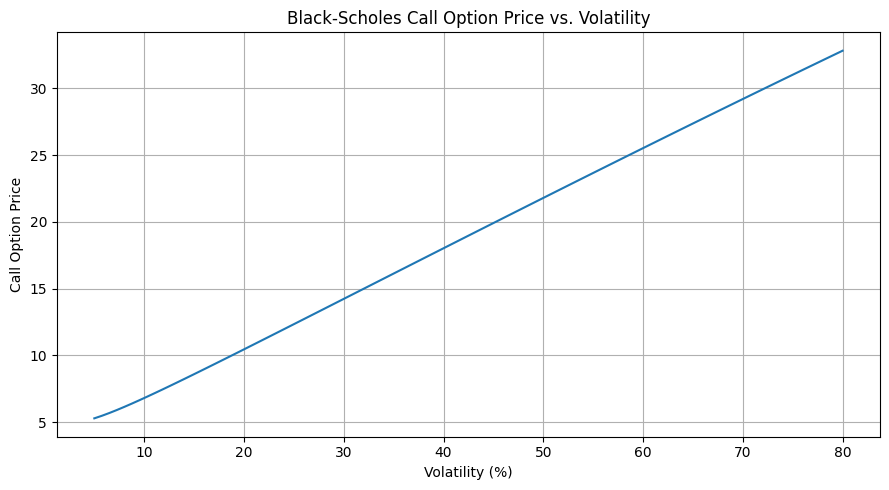

In [47]:
volatilities = np.linspace(0.05, 0.80, 100)

call_prices = [black_schole_prices(100, 100, 1, 0.05, vol, "call") for vol in volatilities]

plt.figure(figsize=(9, 5))
plt.plot(volatilities * 100, call_prices)
plt.xlabel("Volatility (%)")
plt.ylabel("Call Option Price")
plt.title("Black-Scholes Call Option Price vs. Volatility")
plt.grid(True)
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

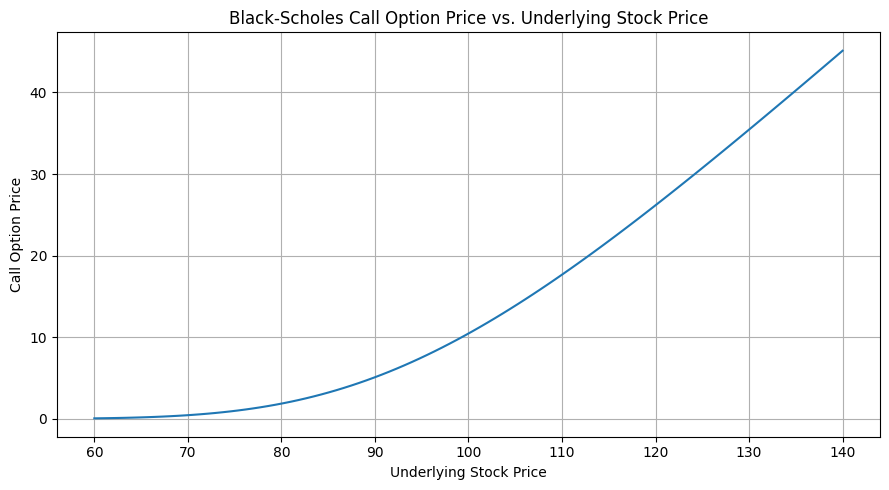

In [48]:
stock_prices = np.linspace(60, 140, 100)

call_prices_by_stock = [black_schole_prices(stock, 100, 1, 0.05, 0.20, "call") for stock in Stock_prices]

plt.figure(figsize=(9, 5))
plt.plot(stock_prices, call_prices_by_stock)
plt.xlabel("Underlying Stock Price")
plt.ylabel("Call Option Price")
plt.title("Black-Scholes Call Option Price vs. Underlying Stock Price")
plt.grid(True)
plt.tight_layout()
plt.show

In [49]:
S = 100
K = 100
T = 1.0
r = 0.05

scenarios = {
    "Low Volatility (10%)": 0.10,
    "Medium Volatility (20%)": 0.20,
    "High Volatility (40%)": 0.40
}

results = []

for scenario, sigma in scenarios.items():
  call = black_schole_prices(S, K, T, r, sigma, option_type="call")
  put = black_schole_prices(S, K, T, r, sigma, option_type="put")

  results.append({
      "Scenario": scenario,
      "Volatility": sigma,
      "Call Price": call,
      "Put Price": put
  })

for results in results:
  print(
      f"result['Scenario']"
      f"Call = {results['Call Price']:.4f}"
      f"Put = {results['Put Price']:.4f}"
  )

result['Scenario']Call = 6.8050Put = 1.9279
result['Scenario']Call = 10.4506Put = 5.5735
result['Scenario']Call = 18.0230Put = 13.1459


In [50]:
for sigma in [0.10, 0.20, 0.40]:
  call = black_scholes_price(100, 100, 1, 0.05, sigma, "call")
  put = black_scholes_price(100, 100, 1, 0.05, sigma, "put")

  parity_lhs = call - put
  parity_rhs = 100 - 100 * np.exp(-0.05)

  assert np.isclose(parity_lhs, parity_rhs)

  assert 0 <= call <= 100
  assert 0 <= put <= 100

  print("All final validation tests passed!")

All final validation tests passed!
All final validation tests passed!
All final validation tests passed!
